In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os, csv, time
from dataclasses import dataclass, field
from typing import Any, Dict, List, Tuple

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Normal

from utils import *

/opt/anaconda3/envs/pettingzoo/lib/python3.10/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [3]:
@dataclass
class PPOConfig:
    # env / rollout
    num_envs: int = 8
    T: int = 512

    # recurrent PPO
    seq_len: int = 24
    epochs: int = 4
    n_seq_minibatch: int = 16

    # PPO
    gamma: float = 0.99
    lam: float = 0.95
    clip_coef: float = 0.2
    vf_coef: float = 0.5

    ent_coef_start: float = 0.01
    ent_coef_end: float = 0.001
    ent_decay_frac: float = 0.6

    target_kl: float = 0.03
    max_grad_norm: float = 1.0

    actor_lr: float = 1e-4
    critic_lr: float = 2e-4

    num_updates: int = 500
    print_every: int = 20
    eval_every: int = 100
    eval_episodes: int = 5

    obs_rms_warmup_steps: int = 5000
    reward_norm: bool = True
    reward_clip: float = 5.0

    # communication
    msg_dim: int = 16
    k_neighbors: int = 2
    msg_dropout_p: float = 0.1

    # coordination
    n_coop: int = 2

In [ ]:
@dataclass
class StatsLogger:
    rows: List[Dict[str, Any]] = field(default_factory=list)

    def log_progress(self, update: int, env_steps: int, episodes: int):
        """Start a new row (one row = one logging point)."""
        self.rows.append({
            "update": int(update),
            "env_steps": int(env_steps),
            "episodes": int(episodes),
        })

    def _ensure_row(self):
        if not self.rows:
            self.rows.append({})

    def log(self, key: str, value: Any):
        self._ensure_row()
        self.rows[-1][key] = value

    def log_dict(self, d: Dict[str, Any]):
        self._ensure_row()
        self.rows[-1].update(d)

    def save_npz(self, path: str):
        keys = sorted({k for r in self.rows for k in r.keys()})
        out = {}
        for k in keys:
            col = [r.get(k, np.nan) for r in self.rows]
            try:
                out[k] = np.array(col, dtype=np.float32)
            except Exception:
                out[k] = np.array(col, dtype=object)
        np.savez(path, **out)
        print(f"Saved logs to {path}")

    def save_csv(self, path: str):
        if not self.rows:
            print("No logs to save.")
            return
        keys = sorted({k for r in self.rows for k in r.keys()})
        with open(path, "w", newline="") as f:
            w = csv.DictWriter(f, fieldnames=keys)
            w.writeheader()
            for r in self.rows:
                w.writerow(r)
        print(f"Saved logs to {path}")

In [5]:
def plot_key(logger: StatsLogger, key: str, x_key: str = "env_steps",
             title: str | None = None, y_std_key: str | None = None):
    if not logger.rows:
        print("No rows in logger."); 
        return

    xs, ys, ystd = [], [], []
    for r in logger.rows:
        if x_key in r and key in r:
            xs.append(float(r[x_key]))
            ys.append(float(r[key]))
            if y_std_key is not None and y_std_key in r:
                ystd.append(float(r[y_std_key]))

    if len(xs) == 0:
        print(f"Missing {key} or {x_key} in rows")
        return

    xs = np.array(xs, dtype=np.float32)
    ys = np.array(ys, dtype=np.float32)

    plt.figure()
    plt.plot(xs, ys)

    if y_std_key is not None and len(ystd) == len(xs):
        ystd = np.array(ystd, dtype=np.float32)
        plt.fill_between(xs, ys - ystd, ys + ystd, alpha=0.2)

    plt.title(title or f"{key} vs {x_key}")
    plt.xlabel(x_key)
    plt.ylabel(key)
    plt.grid(True, alpha=0.3)
    plt.show()

In [ ]:
class RecurrentPolicy(nn.Module):
    def __init__(self, obs_dim, act_dim, msg_dim=16, hidden=128, msg_dropout_p=0.1):
        super().__init__()
        self.obs_dim = obs_dim
        self.act_dim = act_dim
        self.msg_dim = msg_dim
        self.hidden = hidden
        self.msg_dropout_p = msg_dropout_p

        self.pre = nn.Sequential(
            nn.Linear(obs_dim + msg_dim, hidden),
            nn.Tanh()
        )
        self.gru = nn.GRUCell(hidden, hidden)

        self.mean = nn.Linear(hidden, act_dim)
        self.logstd = nn.Parameter(torch.zeros(act_dim))

        #  communication 
        self.msg_latent = nn.Linear(hidden, msg_dim - 3)
        self.msg_explicit = nn.Linear(hidden, 3)

        self.gate_head = nn.Linear(hidden, msg_dim)

    def init_hidden(self, B, device):
        return torch.zeros((B, self.hidden), device=device)

    def forward_step(self, obs, msg_in, h):
        if self.training and self.msg_dropout_p > 0:
            mask = (torch.rand_like(msg_in) > self.msg_dropout_p).float()
            msg_in = msg_in * mask

        x = torch.cat([obs, msg_in], dim=-1)
        x = self.pre(x)
        h2 = self.gru(x, h)

        mean = self.mean(h2)
        std = torch.exp(self.logstd).unsqueeze(0).expand_as(mean)

        latent = torch.tanh(self.msg_latent(h2))
        explicit = torch.sigmoid(self.msg_explicit(h2))
        msg_out = torch.cat([latent, explicit], dim=-1)

        gate = torch.sigmoid(self.gate_head(h2))

        return mean, std, msg_out, gate, h2
    

class CentralCritic(nn.Module):
    def __init__(self, obs_dim, B, hidden=256):
        super().__init__()
        self.B = B
        self.net = nn.Sequential(
            nn.Linear(obs_dim * B, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, B)
        )

    def forward(self, obs_all):
        E, B, D = obs_all.shape
        return self.net(obs_all.reshape(E, B * D))

In [ ]:
def food_signal_from_obs(obs_np):
    food_part = obs_np[:, :20]   # Waterworld sensors (OK par défaut)
    strength = np.linalg.norm(food_part, axis=1, keepdims=True)
    detected = (strength > 0.1).astype(np.float32)
    return detected, np.clip(strength, 0, 1)


def local_broadcast_help_weighted(msgs, neigh_idx):
    help_signal = msgs[:, -3:-2] + 1e-3
    out = np.zeros_like(msgs)
    for i in range(len(msgs)):
        w = help_signal[neigh_idx[i]]
        out[i] = (msgs[neigh_idx[i]] * w).sum(axis=0) / w.sum()
    return out

In [ ]:
def save_ckpt(path: str, cfg: PPOConfig, env_kwargs: dict, seed: int,
              policy: RecurrentPolicy, critic: CentralCritic,
              obs_rms: RunningMeanStd, rew_rms: RunningMeanStd,
              obs_dim: int, act_dim: int, logger: StatsLogger, B: int):
    ckpt = {
        "policy_state": policy.state_dict(),
        "critic_state": critic.state_dict(),
        "obs_rms": obs_rms.state_dict(),
        "rew_rms": rew_rms.state_dict(),
        "cfg": cfg.__dict__,
        "env_kwargs": env_kwargs,
        "seed": seed,
        "obs_dim": obs_dim,
        "act_dim": act_dim,
        "msg_dim": cfg.msg_dim,
        "hidden": policy.hidden,
        "B": int(B),

        "logs": logger.rows,
    }
    torch.save(ckpt, path)


@torch.no_grad()
def load_ckpt(path: str, device: torch.device):
    ckpt = torch.load(path, map_location=device)

    cfg = PPOConfig(**ckpt["cfg"])
    obs_dim = ckpt["obs_dim"]
    act_dim = ckpt["act_dim"]
    B = int(ckpt.get("B", ckpt["env_kwargs"].get("n_pursuers", 5)))

    policy = RecurrentPolicy(
        obs_dim, act_dim,
        msg_dim=ckpt.get("msg_dim", cfg.msg_dim),
        hidden=ckpt.get("hidden", 128),
        msg_dropout_p=cfg.msg_dropout_p
    ).to(device)
    policy.load_state_dict(ckpt["policy_state"])
    policy.eval()

    critic = CentralCritic(obs_dim, B=B).to(device)
    critic.load_state_dict(ckpt["critic_state"])
    critic.eval()

    obs_rms = RunningMeanStd(shape=(obs_dim,), device=device)
    obs_rms.load_state_dict(ckpt["obs_rms"])

    rew_rms = RunningMeanStd(shape=(), device=device)
    rew_rms.load_state_dict(ckpt["rew_rms"])

    logger = StatsLogger()
    logger.rows = ckpt.get("logs", [])

    return cfg, ckpt["env_kwargs"], ckpt["seed"], policy, critic, obs_rms, rew_rms, logger

In [ ]:
def train(cfg: PPOConfig, env_kwargs: dict, model_path: str, seed: int = 0, logs_prefix: str = "ww_logs"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    np.random.seed(seed)
    torch.manual_seed(seed)

    env_steps_total = 0    
    episodes_total = 0  

    vec = VecParallel(env_kwargs, cfg.num_envs, seed=seed)
    obs_dim, act_dim, B = vec.obs_dim, vec.act_dim, vec.B
    print("obs_dim:", obs_dim, "act_dim:", act_dim, "B:", B)

    policy = RecurrentPolicy(obs_dim, act_dim, msg_dim=cfg.msg_dim, hidden=128, msg_dropout_p=cfg.msg_dropout_p).to(device)
    critic = CentralCritic(obs_dim, B=B, hidden=256).to(device)

    opt_pi = optim.Adam(policy.parameters(), lr=cfg.actor_lr)
    opt_v  = optim.Adam(critic.parameters(), lr=cfg.critic_lr)

    obs_rms = RunningMeanStd(shape=(obs_dim,), device=device)
    rew_rms = RunningMeanStd(shape=(), device=device)

    warmup_obs_rms(vec, obs_rms, steps=cfg.obs_rms_warmup_steps, seed=seed)

    logger = StatsLogger()

    h = policy.init_hidden(cfg.num_envs * B, device).reshape(cfg.num_envs, B, -1)
    msg_prev = np.zeros((cfg.num_envs, B, cfg.msg_dim), dtype=np.float32)

    ep_returns = torch.zeros((cfg.num_envs, B), device=device)
    finished_eps: List[float] = []

    def ent_schedule(it: int) -> float:
        frac = min(1.0, it / max(1.0, cfg.ent_decay_frac * cfg.num_updates))
        return cfg.ent_coef_start + frac * (cfg.ent_coef_end - cfg.ent_coef_start)

    for it in range(1, cfg.num_updates + 1):
        ent_coef = ent_schedule(it)
        policy.train()
        critic.train()

        
        obs_buf   = torch.zeros((cfg.T, cfg.num_envs, B, obs_dim), device=device)
        msgin_buf = torch.zeros((cfg.T, cfg.num_envs, B, cfg.msg_dim), device=device)
        h_buf     = torch.zeros((cfg.T, cfg.num_envs, B, policy.hidden), device=device)

        u_buf        = torch.zeros((cfg.T, cfg.num_envs, B, act_dim), device=device)
        logp_old_buf = torch.zeros((cfg.T, cfg.num_envs, B), device=device)
        val_buf      = torch.zeros((cfg.T, cfg.num_envs, B), device=device)
        rew_buf      = torch.zeros((cfg.T, cfg.num_envs, B), device=device)
        done_buf     = torch.zeros((cfg.T, cfg.num_envs, B), device=device)

        rollout_sum = torch.zeros((cfg.num_envs, B), device=device)

        msg_norm_roll, gate_mean_roll = 0.0, 0.0

        with torch.no_grad():
            for t in range(cfg.T):
                O_np_raw = vec.obs_batch_np()  


                msg_in_np = np.zeros((cfg.num_envs, B, cfg.msg_dim), dtype=np.float32)

                for ei in range(cfg.num_envs):
                    obs_e = O_np_raw[ei]
                    neigh = knn_neighbors_from_obs(obs_e, k=min(cfg.k_neighbors, B-1))

                    msg_in_np[ei] = local_broadcast_help_weighted(
                        msg_prev[ei],
                        neigh
                    )

                food_det, food_str = food_signal_from_obs(O_np_raw[ei])
                coop_missing = np.maximum(cfg.n_coop - food_det.sum(), 0) / cfg.n_coop

                explicit = np.concatenate([food_det, coop_missing*np.ones_like(food_det), food_str], axis=-1)

                msg_prev[ei][:, -3:] = explicit

                O = torch.tensor(O_np_raw, dtype=torch.float32, device=device)
                O = obs_rms.normalize(O)
                M = torch.tensor(msg_in_np, dtype=torch.float32, device=device)

                h_buf[t] = h
                obs_buf[t] = O
                msgin_buf[t] = M

                v = critic(O)
                val_buf[t] = v

                O_flat = O.reshape(cfg.num_envs * B, obs_dim)
                M_flat = M.reshape(cfg.num_envs * B, cfg.msg_dim)
                h_flat = h.reshape(cfg.num_envs * B, policy.hidden)

                mean, std, msg_out, gate, h2 = policy.forward_step(O_flat, M_flat, h_flat)
                dist = Normal(mean, std)

                eps = torch.randn_like(mean)
                u = mean + std * eps
                a = torch.tanh(u)

                logp = tanh_gaussian_logprob(dist, u, a)

                u_buf[t] = u.reshape(cfg.num_envs, B, act_dim)
                logp_old_buf[t] = logp.reshape(cfg.num_envs, B)

                a_np = a.reshape(cfg.num_envs, B, act_dim).cpu().numpy().astype(np.float32)
                rew_np, done_np, reset_flags = vec.step(a_np, reset_seed_offset=50_000 + it * 17)

                env_steps_total += cfg.num_envs * B

                r = torch.tensor(rew_np, dtype=torch.float32, device=device)
                d = torch.tensor(done_np, dtype=torch.float32, device=device)

                rollout_sum += r
                ep_returns += r

                if cfg.reward_norm:
                    rew_rms.update(r.reshape(-1))
                    r_train = rew_rms.normalize(r, clip=cfg.reward_clip)
                else:
                    r_train = r

                rew_buf[t] = r_train
                done_buf[t] = d

                h2_e = h2.reshape(cfg.num_envs, B, policy.hidden)
                h = h2_e * (1.0 - d).unsqueeze(-1)

                msg_out_e = msg_out.reshape(cfg.num_envs, B, cfg.msg_dim).cpu().numpy().astype(np.float32)
                msg_prev = msg_out_e

                msg_norm_roll += float(np.mean(np.abs(msg_out_e)))
                gate_mean_roll += float(gate.mean().item())

                for ei, did_reset in enumerate(reset_flags):
                    if did_reset:
                        episodes_total += 1
                        finished_eps.append(ep_returns[ei].mean().item())
                        ep_returns[ei].zero_()
                        h[ei].zero_()
                        msg_prev[ei].fill(0.0)


            O_last_np = vec.obs_batch_np()
            O_last = torch.tensor(O_last_np, dtype=torch.float32, device=device)
            O_last = obs_rms.normalize(O_last)
            v_last = critic(O_last)

        adv_buf, ret_buf = compute_gae(rew_buf, done_buf, val_buf, v_last, cfg.gamma, cfg.lam)
        adv = (adv_buf - adv_buf.mean()) / (adv_buf.std() + 1e-8)
        adv = adv.detach()
        ret = ret_buf.detach()


        T = cfg.T
        L = cfg.seq_len
        EB = cfg.num_envs * B
        n_starts = T - L + 1
        all_pairs = np.array([(eb, st) for eb in range(EB) for st in range(n_starts)], dtype=np.int32)

        approx_kl = 0.0
        clipfrac_last = 0.0
        pi_loss_last, v_loss_last, ent_last = 0.0, 0.0, 0.0
        early_stop = False

        for ep in range(cfg.epochs):
            perm = np.random.permutation(len(all_pairs))
            for mb_start in range(0, len(all_pairs), cfg.n_seq_minibatch):
                mb_idx = perm[mb_start:mb_start + cfg.n_seq_minibatch]
                batch = all_pairs[mb_idx]
                if len(batch) == 0:
                    continue

                Bseq = len(batch)

                O_seq = torch.zeros((Bseq, L, obs_dim), device=device)
                M_seq = torch.zeros((Bseq, L, cfg.msg_dim), device=device)
                U_seq = torch.zeros((Bseq, L, act_dim), device=device)
                LOGP_old = torch.zeros((Bseq, L), device=device)
                ADV = torch.zeros((Bseq, L), device=device)
                DONE = torch.zeros((Bseq, L), device=device)
                H0 = torch.zeros((Bseq, policy.hidden), device=device)

                for i, (eb, st) in enumerate(batch):
                    e = int(eb // B)
                    b = int(eb % B)
                    O_seq[i] = obs_buf[st:st+L, e, b]
                    M_seq[i] = msgin_buf[st:st+L, e, b]
                    U_seq[i] = u_buf[st:st+L, e, b]
                    LOGP_old[i] = logp_old_buf[st:st+L, e, b]
                    ADV[i] = adv[st:st+L, e, b]
                    DONE[i] = done_buf[st:st+L, e, b]
                    H0[i] = h_buf[st, e, b]


                h_mb = H0
                logp_new_steps, ent_steps = [], []

                for tt in range(L):
                    mean, std, msg_out, gate, h2 = policy.forward_step(O_seq[:, tt], M_seq[:, tt], h_mb)
                    dist = Normal(mean, std)
                    u_t = U_seq[:, tt]
                    a_t = torch.tanh(u_t)
                    logp_new = tanh_gaussian_logprob(dist, u_t, a_t)
                    ent = dist.entropy().sum(-1)

                    logp_new_steps.append(logp_new)
                    ent_steps.append(ent)

                    d_t = DONE[:, tt]
                    h_mb = h2 * (1.0 - d_t).unsqueeze(-1)

                logp_new = torch.stack(logp_new_steps, dim=1)
                ent_mean = torch.stack(ent_steps, dim=1).mean()

                ratio = torch.exp(logp_new - LOGP_old)
                surr1 = ratio * ADV
                surr2 = torch.clamp(ratio, 1.0 - cfg.clip_coef, 1.0 + cfg.clip_coef) * ADV
                pi_loss = -torch.min(surr1, surr2).mean()

                clipfrac = (torch.abs(ratio - 1.0) > cfg.clip_coef).float().mean().item()

                with torch.no_grad():
                    approx_kl = (LOGP_old - logp_new).mean().item()

                loss_pi_total = pi_loss - ent_coef * ent_mean

                opt_pi.zero_grad(set_to_none=True)
                loss_pi_total.backward()
                nn.utils.clip_grad_norm_(policy.parameters(), cfg.max_grad_norm)
                opt_pi.step()


                n_v = min(256, cfg.T * cfg.num_envs)
                t_idx = torch.randint(low=0, high=cfg.T, size=(n_v,), device=device)
                e_idx = torch.randint(low=0, high=cfg.num_envs, size=(n_v,), device=device)

                O_v = obs_buf[t_idx, e_idx]
                V_pred = critic(O_v)
                V_targ = ret_buf[t_idx, e_idx]
                V_old  = val_buf[t_idx, e_idx]

                V_clipped = V_old + torch.clamp(V_pred - V_old, -cfg.clip_coef, cfg.clip_coef)
                v_loss = 0.5 * torch.max((V_pred - V_targ).pow(2), (V_clipped - V_targ).pow(2)).mean()

                opt_v.zero_grad(set_to_none=True)
                v_loss.backward()
                nn.utils.clip_grad_norm_(critic.parameters(), cfg.max_grad_norm)
                opt_v.step()

                pi_loss_last = float(pi_loss.item())
                v_loss_last = float(v_loss.item())
                ent_last = float(ent_mean.item())
                clipfrac_last = float(clipfrac)

                if cfg.target_kl is not None and approx_kl > cfg.target_kl:
                    early_stop = True
                    break

            if early_stop:
                break


        if it % cfg.print_every == 0:
            rollout_avg = rollout_sum.mean().item()
            rollout_min = rollout_sum.min().item()
            rollout_max = rollout_sum.max().item()
            rollout_std = rollout_sum.std().item()

            if finished_eps:
                window = finished_eps[-max(1, cfg.num_envs * 5):]
                train_ep_avg = float(np.mean(window))
                train_ep_std = float(np.std(window))
                episodes_in_window = len(window)
            else:
                train_ep_avg = float("nan")
                train_ep_std = float("nan")
                episodes_in_window = 0

            msg_norm_roll /= max(1.0, cfg.T)
            gate_mean_roll /= max(1.0, cfg.T)
            logstd_mean = float(policy.logstd.mean().item())

            print(
                f"it={it:4d}  train_ep_avg={train_ep_avg:8.3f}  "
                f"rollout_avg={rollout_avg:8.3f}  [min={rollout_min:8.3f}, max={rollout_max:8.3f}]  "
                f"ent={ent_last:6.3f}  ent_coef={ent_coef:0.4f}  kl={approx_kl:0.4f}  "
                f"clipfrac={clipfrac_last:0.3f}  piL={pi_loss_last:6.3f}  vL={v_loss_last:6.3f}  "
                f"logstd={logstd_mean:0.3f}  msg_norm={msg_norm_roll:0.3f}  gate={gate_mean_roll:0.3f}  "
                f"finished={episodes_in_window}"
                + ("  (KL early stop)" if early_stop else "")
            )

            logger.log_progress(update=it, env_steps=env_steps_total, episodes=episodes_total)
            logger.log_dict({
                "train_ep_avg": train_ep_avg,
                "train_ep_std": train_ep_std,
                "episodes_in_window": float(episodes_in_window),
                "rollout_avg": rollout_avg,
                "rollout_min": rollout_min,
                "rollout_max": rollout_max,
                "rollout_std": rollout_std,
                "entropy": ent_last,
                "ent_coef": ent_coef,
                "approx_kl": approx_kl,
                "clipfrac": clipfrac_last,
                "pi_loss": pi_loss_last,
                "v_loss": v_loss_last,
                "logstd_mean": logstd_mean,
                "msg_norm": msg_norm_roll,
                "gate_mean": gate_mean_roll,
                "early_stop": 1.0 if early_stop else 0.0,
            })

        if it % cfg.eval_every == 0:
            eval_avg = evaluate_recurrent(cfg, env_kwargs, policy, obs_rms, device, seed)
            print(f"  | eval_avg={eval_avg:8.3f}")

            logger.log("eval_avg", float(eval_avg))

            save_ckpt(model_path, cfg, env_kwargs, seed, policy, critic, obs_rms, rew_rms, obs_dim, act_dim, logger, B=B)
            logger.save_npz(f"{logs_prefix}.npz")
            logger.save_csv(f"{logs_prefix}.csv")

    vec.close()
    return policy, critic, obs_rms, rew_rms, logger

In [ ]:
cfg = PPOConfig(
    # ---------- rollout ----------
    num_envs=12,
    T=768,

    # ---------- recurrent PPO ----------
    seq_len=32,
    epochs=4,
    n_seq_minibatch=32,

    # ---------- optimization ----------
    actor_lr=1e-4,
    critic_lr=3e-4,

    # ---------- PPO control ----------
    gamma=0.99,
    lam=0.95,
    clip_coef=0.2,
    target_kl=0.04,

    # ---------- entropy schedule ----------
    ent_coef_start=0.01,
    ent_coef_end=0.002,
    ent_decay_frac=0.6,

    # ---------- run ----------
    num_updates=1000,
    print_every=20,
    eval_every=100,
    eval_episodes=5,

    # ---------- normalization ----------
    obs_rms_warmup_steps=5000,
    reward_norm=True,
    reward_clip=10.0,

    # ---------- communication ----------
    msg_dim=32,
    k_neighbors=2,
    msg_dropout_p=0.1,
)

env_kwargs = dict(
    n_pursuers=5,
    n_evaders=5,
    n_coop=2,
    max_cycles=500,
)

policy, critic, obs_rms, rew_rms, logger = train(
    cfg,
    env_kwargs,
    model_path="waterworld.pt",
    seed=0,
    logs_prefix="logs"
)

obs_dim: 242 act_dim: 2 B: 5
Warmup obs RMS for 5000 steps (random policy), then freeze.
it=  20  train_ep_avg=-103.346  rollout_avg=-152.549  [min=-276.820, max= -83.647]  ent= 2.075  ent_coef=0.0097  kl=0.0405  clipfrac=0.190  piL= 0.316  vL= 3.020  logstd=-0.382  msg_norm=0.186  gate=0.496  finished=60  (KL early stop)
it=  40  train_ep_avg= -65.408  rollout_avg= -98.667  [min=-200.969, max= -21.681]  ent= 1.034  ent_coef=0.0095  kl=0.0490  clipfrac=0.190  piL= 0.367  vL= 4.439  logstd=-0.902  msg_norm=0.185  gate=0.496  finished=60  (KL early stop)
it=  60  train_ep_avg= -44.246  rollout_avg= -67.901  [min=-141.898, max=  -4.267]  ent= 0.196  ent_coef=0.0092  kl=0.0439  clipfrac=0.216  piL= 0.379  vL= 5.051  logstd=-1.321  msg_norm=0.193  gate=0.496  finished=60  (KL early stop)
it=  80  train_ep_avg= -34.265  rollout_avg= -54.288  [min=-121.864, max=  -8.152]  ent=-0.332  ent_coef=0.0089  kl=0.0438  clipfrac=0.223  piL= 0.281  vL= 2.312  logstd=-1.585  msg_norm=0.196  gate=0.495  

In [ ]:
MODEL_PATH = "waterworld.pt" 

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg_loaded, env_kwargs_loaded, seed_loaded, policy_loaded, critic_loaded, obs_rms_loaded, rew_rms_loaded, logger_loaded = load_ckpt(
    MODEL_PATH, device=device
)

print("Loaded seed:", seed_loaded)
print("Loaded cfg:", cfg_loaded)

Loaded seed: 0
Loaded cfg: PPOConfig(num_envs=12, T=768, seq_len=32, epochs=4, n_seq_minibatch=32, gamma=0.99, lam=0.95, clip_coef=0.2, vf_coef=0.5, ent_coef_start=0.01, ent_coef_end=0.002, ent_decay_frac=0.6, target_kl=0.04, max_grad_norm=1.0, actor_lr=0.0001, critic_lr=0.0003, num_updates=1000, print_every=20, eval_every=100, eval_episodes=5, obs_rms_warmup_steps=5000, reward_norm=True, reward_clip=10.0, msg_dim=32, k_neighbors=2, msg_dropout_p=0.1, n_coop=2)


In [ ]:
record_recurrent(
    cfg=cfg_loaded,
    env_kwargs=env_kwargs_loaded,
    model=policy_loaded,
    obs_rms=obs_rms_loaded,
    out_mp4="waterworld.mp4",
    seed=42,
)

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (750, 750) to (752, 752) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Saved video to: ppo_waterworld_coord.mp4


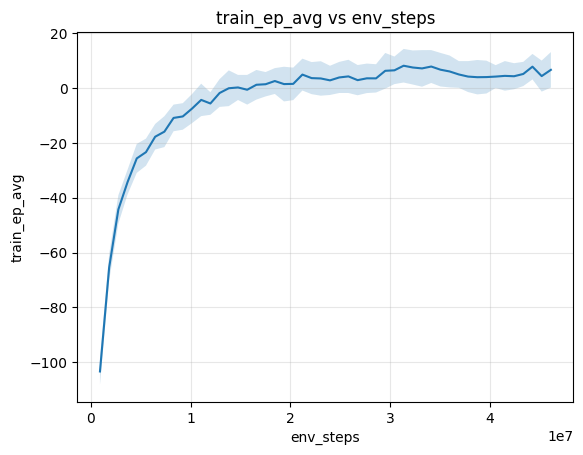

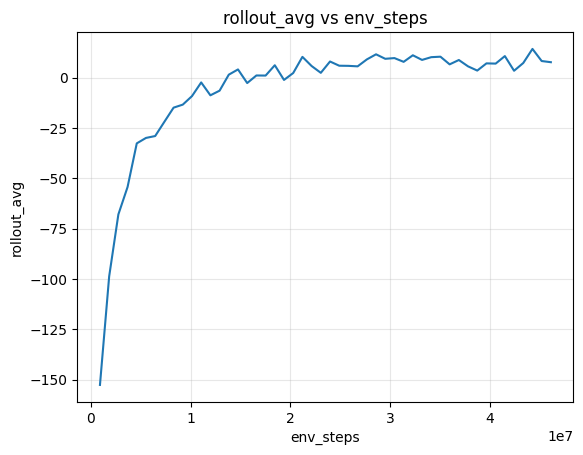

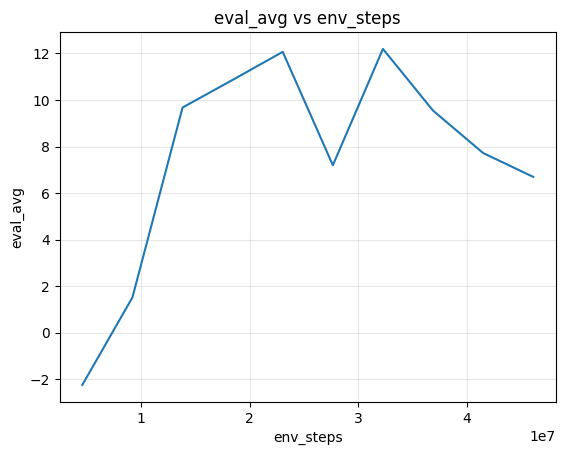

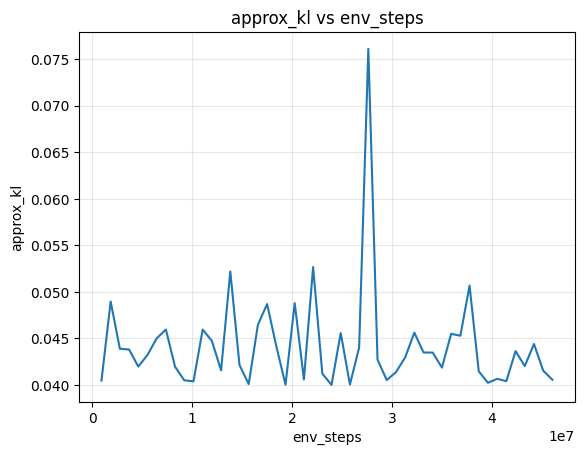

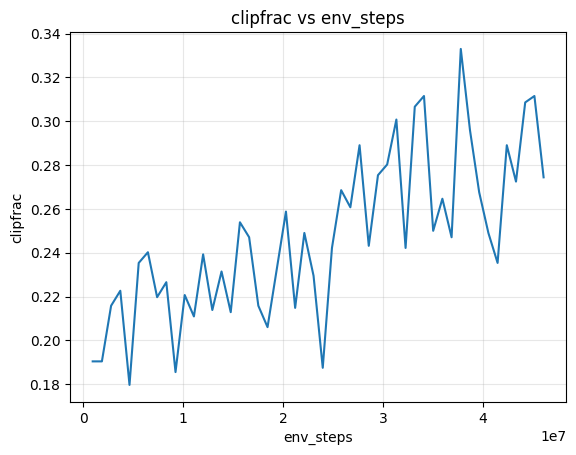

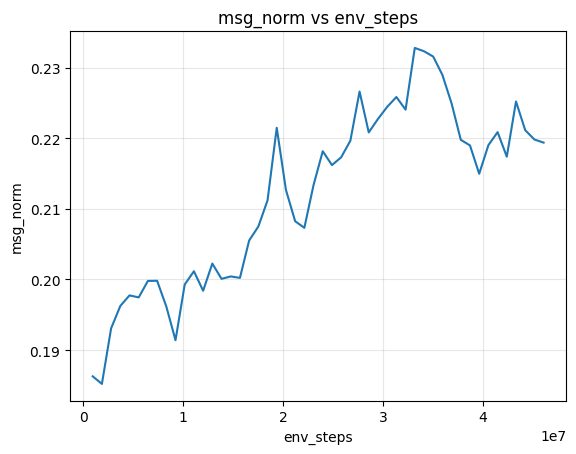

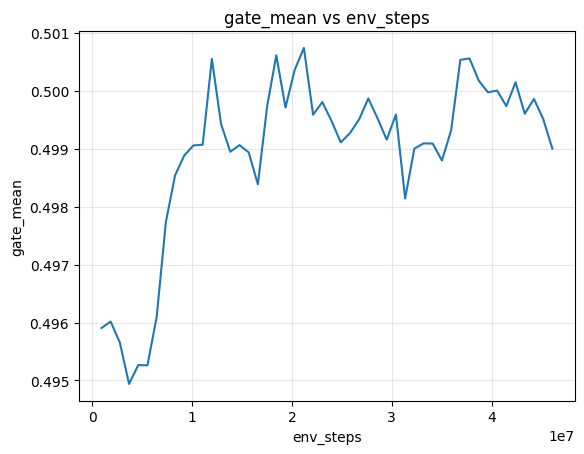

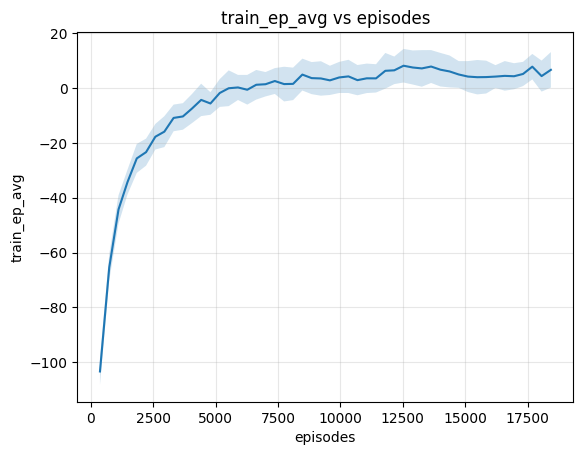

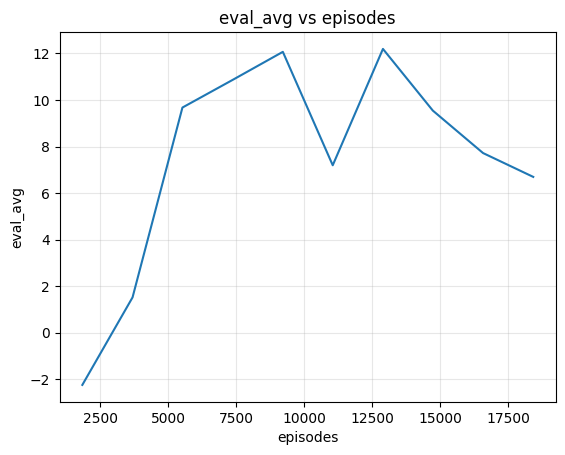

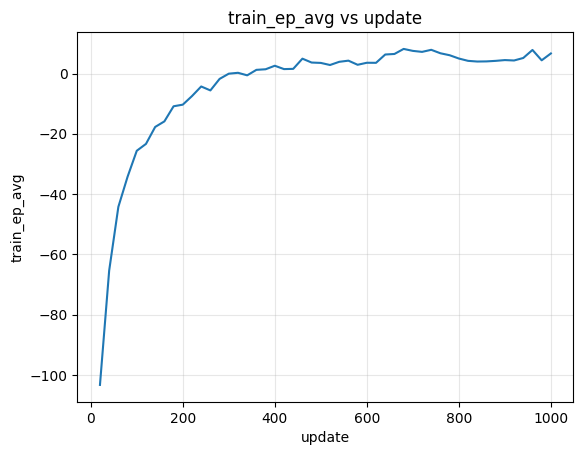

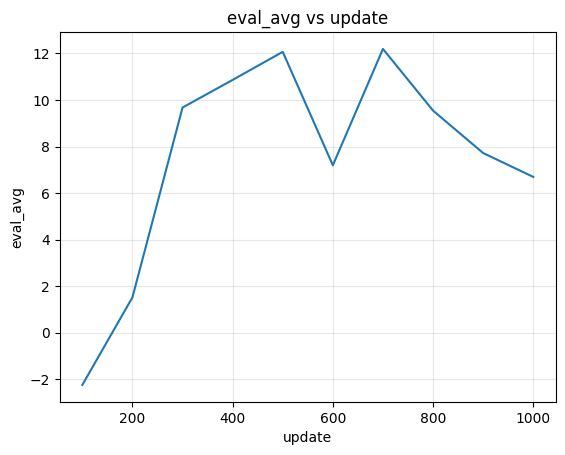

In [ ]:
plot_key(logger, "train_ep_avg", x_key="env_steps", y_std_key="train_ep_std")
plot_key(logger, "rollout_avg",  x_key="env_steps")
plot_key(logger, "eval_avg",     x_key="env_steps")
plot_key(logger, "approx_kl",    x_key="env_steps")
plot_key(logger, "clipfrac",     x_key="env_steps")
plot_key(logger, "msg_norm",     x_key="env_steps")
plot_key(logger, "gate_mean",    x_key="env_steps")

plot_key(logger, "train_ep_avg", x_key="episodes", title="train_ep_avg vs episodes", y_std_key="train_ep_std")
plot_key(logger, "eval_avg",     x_key="episodes", title="eval_avg vs episodes")

plot_key(logger, "train_ep_avg", x_key="update")
plot_key(logger, "eval_avg",     x_key="update")